# Convolution Neural Network (CNN)

A CNN is a deep learning model which is designed for processing grid-like data such as images. In this case, the model will be used to detect whether the MRI image contains a brain tumor, and classify them accordingly.

## Setup

Import libraries needed to load and prepare image data, define and train the CNN, and evaluate its predictions. PyTorch handles the model and training, while scikit-learn provides classification metrics and curve calculations.

In [19]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import math
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import ( 
    classification_report, 
    ConfusionMatrixDisplay, 
    average_precision_score, 
    precision_recall_curve, 
    roc_auc_score, 
    roc_curve,
)
from sklearn.preprocessing import label_binarize

### GPU Setup (NVIDIA CUDA)

This notebook uses **PyTorch** to train a convolutional neural network (CNN). When a CUDA-enabled PyTorch build and a compatible NVIDIA driver are available, training runs on the NVIDIA GPU; otherwise, it falls back to the CPU.

The following pip command was used to install PyTorch in a Jupyter code block:
- ```%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132```

PyTorch was installed in the notebook's Python environment with CUDA support. The CUDA-enabled PyTorch package provides the CUDA runtime it needs. Installing the full CUDA Toolkit separately is generally not required for this notebook.

However, the full toolkit can be accessed here:
- https://developer.nvidia.com/cuda-downloads?target_os=Windows&target_arch=x86_64&target_version=11&target_type=exe_local

Check that PyTorch can access the GPU:

```python
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

## Load data and prepare batches

Load the preprocessed .npz splits. Each file contains grayscale images (X) and string class labels (y). The dataset converts each image to a normalized tensor and each label to an integer, then the data loaders group examples into batches for training and evaluation.

In [3]:
DATA_DIR = Path("../data/processed")

def load_split(name):
    # These project NPZ files were generated locally and store y as object labels.
    with np.load(DATA_DIR / f"{name}.npz", allow_pickle=True) as data:
        images = data["X"]
        labels = data["y"].astype(str)
    return images, labels

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

classes = sorted(set(y_train))
label_to_id = {label: i for i, label in enumerate(classes)}

def encode_labels(labels):
    return np.array([label_to_id[label] for label in labels], dtype=np.int64)

class MRIDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images  # Keep uint8 in memory; convert per image in __getitem__.
        self.labels = encode_labels(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index].astype(np.float32)
        image_min, image_max = image.min(), image.max()
        image = (image - image_min) / (image_max - image_min + 1e-8)
        image = torch.from_numpy(image).unsqueeze(0)  # (1, 224, 224)
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return image, label

train_loader = DataLoader(
    MRIDataset(X_train, y_train), batch_size=32, shuffle=True
)
val_loader = DataLoader(
    MRIDataset(X_val, y_val), batch_size=32, shuffle=False
)
test_loader = DataLoader(
    MRIDataset(X_test, y_test), batch_size=32, shuffle=False
)

print("Classes:", classes)
print("Training images:", len(X_train))

Classes: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Training images: 4728


## Define CNN

In [4]:
class BrainTumorCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BrainTumorCNN(num_classes=len(classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("Using:", device)

Using: cuda


## Train and keep best validation checkpoint

Ideally, across epochs:

- Training loss generally decreases, and training accuracy generally increases.
- Validation loss decreases too, while validation accuracy improves. These can fluctuate a little from epoch to epoch.
- Training and validation results stay reasonably close. If training keeps improving while validation loss rises or validation accuracy stalls, the model may be overfitting.

In [5]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += labels.size(0)

    return total_loss / count, correct / count

max_epochs = 50
early_stopping_patience = 12
min_delta = 1e-4

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    threshold=min_delta,
    threshold_mode="abs",
    min_lr=1e-6,
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

best_val_loss = float("inf")
epochs_without_improvement = 0
best_state = None

for epoch in range(1, max_epochs + 1):
    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_count += labels.size(0)

    train_loss = train_loss_total / train_count
    train_accuracy = train_correct / train_count
    val_loss, val_accuracy = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
    else:
        epochs_without_improvement += 1

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch {epoch:02d}/{max_epochs} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.3f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.3f} | "
        f"lr {current_lr:.2e}"
    )

    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping after epoch {epoch}.")
        break

assert best_state is not None, "Training did not produce a valid checkpoint."
model.load_state_dict(best_state)

print(f"Best validation loss: {best_val_loss:.4f}")

Epoch 01/50 | train loss 0.8184, accuracy 0.662 | val loss 0.5689, accuracy 0.777 | lr 1.00e-03
Epoch 02/50 | train loss 0.5767, accuracy 0.775 | val loss 0.4242, accuracy 0.846 | lr 1.00e-03
Epoch 03/50 | train loss 0.4936, accuracy 0.809 | val loss 0.7847, accuracy 0.683 | lr 1.00e-03
Epoch 04/50 | train loss 0.4340, accuracy 0.832 | val loss 0.3388, accuracy 0.877 | lr 1.00e-03
Epoch 05/50 | train loss 0.3906, accuracy 0.847 | val loss 0.4526, accuracy 0.842 | lr 1.00e-03
Epoch 06/50 | train loss 0.3864, accuracy 0.852 | val loss 0.3502, accuracy 0.890 | lr 1.00e-03
Epoch 07/50 | train loss 0.3696, accuracy 0.860 | val loss 0.5476, accuracy 0.783 | lr 5.00e-04
Epoch 08/50 | train loss 0.3130, accuracy 0.880 | val loss 0.3605, accuracy 0.873 | lr 5.00e-04
Epoch 09/50 | train loss 0.2914, accuracy 0.891 | val loss 0.2493, accuracy 0.909 | lr 5.00e-04
Epoch 10/50 | train loss 0.2764, accuracy 0.896 | val loss 0.3442, accuracy 0.890 | lr 5.00e-04
Epoch 11/50 | train loss 0.2798, accurac

### Learning curve plot

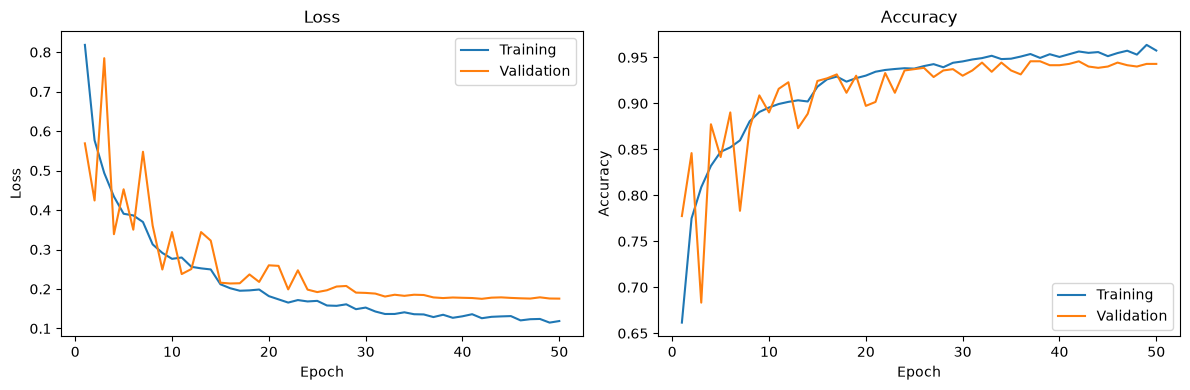

In [6]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate once on held-out test split

In [7]:
model.eval()
y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1)

        y_pred.extend(logits.argmax(dim=1).cpu().numpy())
        y_true.extend(labels.numpy())
        y_prob.extend(probabilities.cpu().numpy())

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(classes)),
    target_names=classes,
    zero_division=0,
))

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

              precision    recall  f1-score   support

      glioma       0.97      0.74      0.84       386
  meningioma       0.84      0.84      0.84       398
     notumor       0.82      1.00      0.90       400
   pituitary       0.96      0.97      0.97       400

    accuracy                           0.89      1584
   macro avg       0.90      0.89      0.89      1584
weighted avg       0.90      0.89      0.89      1584



### Confusion Matrix

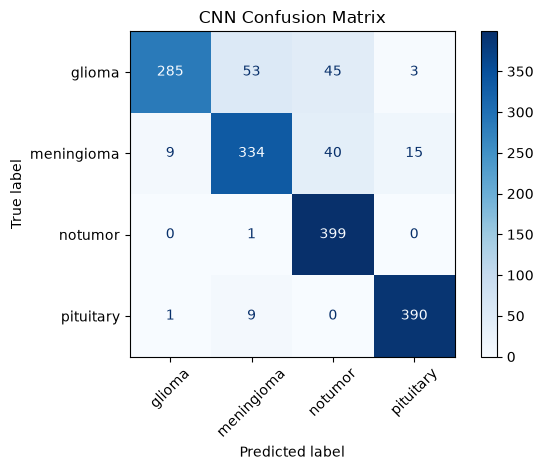

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=range(len(classes)),
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
)
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

## One-vs-rest ROC and Precision-Recall curves

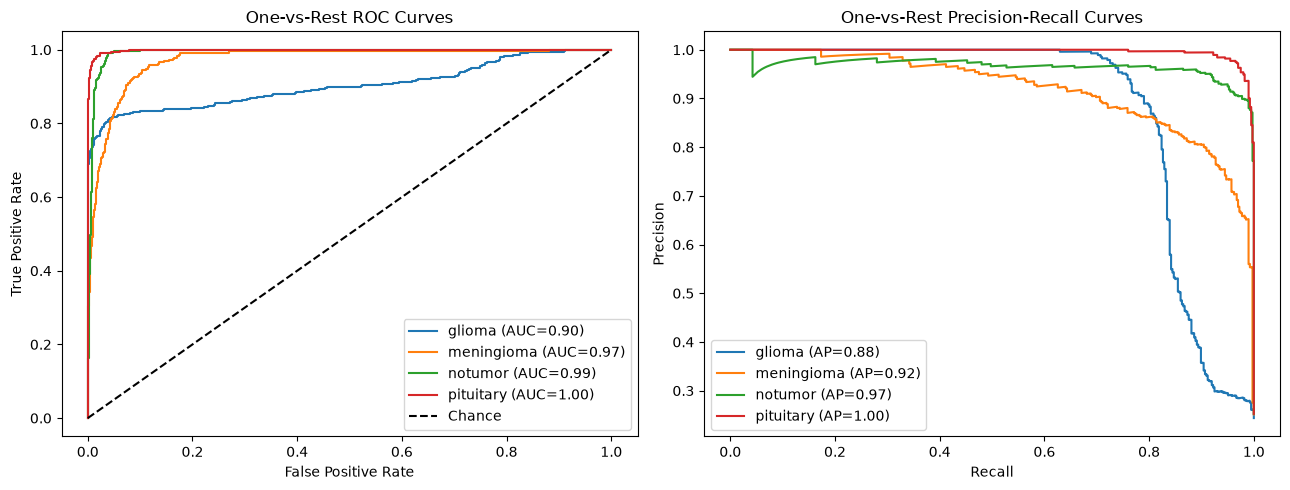

In [9]:
y_test_binary = label_binarize(y_true, classes=range(len(classes)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_prob[:, i])
    roc_auc = roc_auc_score(y_test_binary[:, i], y_prob[:, i])
    axes[0].plot(fpr, tpr, label=f"{class_name} (AUC={roc_auc:.2f})")

    precision, recall, _ = precision_recall_curve(
        y_test_binary[:, i], y_prob[:, i]
    )
    average_precision = average_precision_score(
        y_test_binary[:, i], y_prob[:, i]
    )
    axes[1].plot(
        recall,
        precision,
        label=f"{class_name} (AP={average_precision:.2f})",
    )

axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set(title="One-vs-Rest ROC Curves", xlabel="False Positive Rate",
            ylabel="True Positive Rate")
axes[1].set(title="One-vs-Rest Precision-Recall Curves",
            xlabel="Recall", ylabel="Precision")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

## Show correct and incorrect example predictions

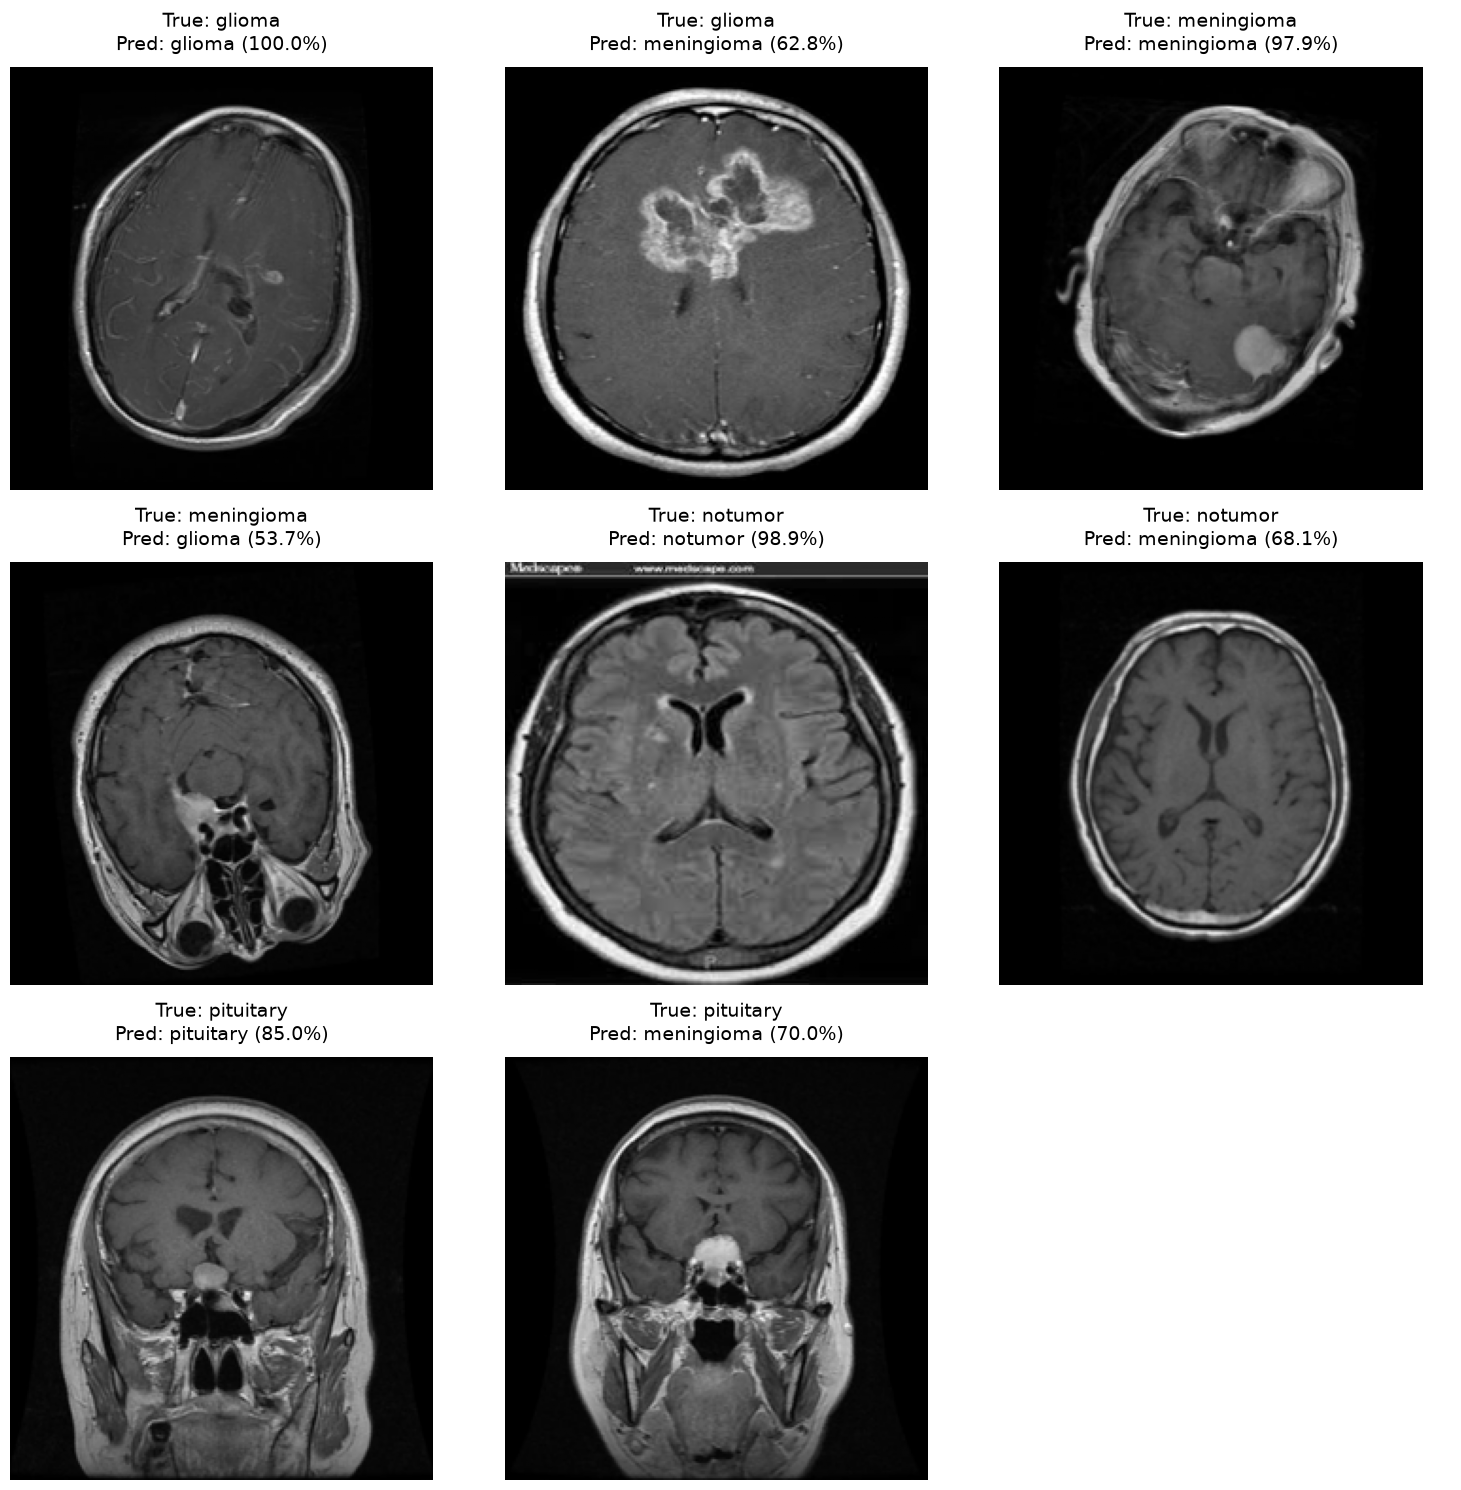

In [21]:
example_indices = []

for class_id in range(len(classes)):
    correct = np.flatnonzero(
        (y_true == class_id) & (y_pred == class_id)
    )[:1]
    incorrect = np.flatnonzero(
        (y_true == class_id) & (y_pred != class_id)
    )[:1]

    example_indices.extend(correct)
    example_indices.extend(incorrect)

example_indices = np.array(example_indices, dtype=int)

if len(example_indices) == 0:
    print("No examples to display.")
else:
    ncols = min(3, len(example_indices))
    nrows = math.ceil(len(example_indices) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 5 * nrows),
        squeeze=False,
    )

    for ax, index in zip(axes.flat, example_indices):
        image, _ = test_loader.dataset[int(index)]
        confidence = y_prob[index, y_pred[index]]

        ax.imshow(image.squeeze(0).numpy(), cmap="gray")
        ax.set_title(
            f"True: {classes[y_true[index]]}\n"
            f"Pred: {classes[y_pred[index]]} ({confidence:.1%})",
            fontsize=14,
            pad=12,
        )
        ax.axis("off")

    for ax in axes.flat[len(example_indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()